In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
!wget $data -O data-week-3-lead.csv

--2026-11-04 12:17:50--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data-week-3-lead.csv’

data-week-3-lead.cs 100%[===================>] 272.21K  --.-KB/s    in 0.002s  

2026-11-04 12:17:50 (125 MB/s) - ‘data-week-3-lead.csv’ saved [278746/278746]



In [3]:
df = pd.read_csv('data-week-3-lead.csv')

In [4]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [5]:
df.columns = df.columns.str.lower().str.replace(' ' , '_')

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
categorical_columns  = list(df.dtypes[df.dtypes == 'str'].index)
categorical_columns 

['lead_source', 'industry', 'employment_status', 'location']

In [8]:
for c in categorical_columns:
    df[c]=df[c].str.lower().str.replace(' ' , '_')

In [9]:
df.converted.value_counts()

converted
1    2883
0    2117
Name: count, dtype: int64

In [10]:
df['converted'].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [11]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [12]:
for col in categorical_columns:
    print(col)
    print(df[col].value_counts())
    print()

lead_source
lead_source
organic_search    1251
paid_ads          1140
social_media      1055
referral           790
events             616
Name: count, dtype: int64

industry
industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64

employment_status
employment_status
employed         2633
student           760
self_employed     715
unemployed        698
Name: count, dtype: int64

location
location
north_america    1371
europe           1149
asia             1052
south_america     749
africa            471
Name: count, dtype: int64



In [13]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [14]:
df.groupby('lead_source')['converted'].mean()

lead_source
events            0.418831
organic_search    0.677858
paid_ads          0.434211
referral          0.763291
social_media      0.563981
Name: converted, dtype: float64

In [15]:
df.groupby('industry')['converted'].mean()

industry
education        0.514867
finance          0.600000
healthcare       0.564286
manufacturing    0.565875
retail           0.557838
technology       0.618926
Name: converted, dtype: float64

In [16]:
df.groupby('employment_status')['converted'].mean()

employment_status
employed         0.666920
self_employed    0.552448
student          0.428947
unemployed       0.419771
Name: converted, dtype: float64

In [17]:
df.groupby('location')['converted'].mean()

location
africa           0.539278
asia             0.592205
europe           0.598782
north_america    0.579869
south_america    0.538051
Name: converted, dtype: float64

In [18]:
df.groupby('converted')['annual_income'].mean()

converted
0    49920.713312
1    57765.179581
Name: annual_income, dtype: float64

In [19]:
df.groupby('number_of_courses_viewed')['converted'].mean()

number_of_courses_viewed
0    0.200422
1    0.385042
2    0.587101
3    0.731023
4    0.877996
5    0.951923
6    1.000000
Name: converted, dtype: float64

In [20]:
df.groupby('number_of_courses_viewed')['converted'].count()

number_of_courses_viewed
0     474
1    1083
2    1659
3    1212
4     459
5     104
6       9
Name: converted, dtype: int64

In [21]:
df.groupby('interaction_count')['converted'].mean()

interaction_count
0     0.095406
1     0.276923
2     0.351626
3     0.402174
4     0.551250
5     0.651629
6     0.767228
7     0.823529
8     0.872587
9     0.931507
10    0.939024
11    0.967742
12    1.000000
13    1.000000
Name: converted, dtype: float64

In [22]:
df.groupby('interaction_count')['converted'].count()

interaction_count
0     283
1     325
2     492
3     644
4     800
5     798
6     653
7     476
8     259
9     146
10     82
11     31
12      8
13      3
Name: converted, dtype: int64

In [23]:
df[['annual_income', 'lead_score']].agg(['mean', 'median'])

,annual_income,lead_score
mean,54533.212049,0.494767
median,55051.000000,0.490000


In [24]:
from sklearn.model_selection import train_test_split

In [25]:
(df.isnull().sum() / len(df)) * 100

lead_source                 2.96
industry                    4.80
employment_status           3.88
location                    4.16
annual_income               7.38
number_of_courses_viewed    0.00
interaction_count           0.00
lead_score                  0.70
converted                   0.00
dtype: float64

In [26]:
df.dropna().shape

(3909, 9)

In [27]:
df['annual_income'].median()

np.float64(55051.0)

In [28]:
df.annual_income = df.annual_income.fillna(df['annual_income'].median())

In [29]:
df['annual_income'].isnull().sum()

np.int64(0)

In [30]:
df['lead_score'].agg(['mean', 'median'])

mean      0.494767
median    0.490000
Name: lead_score, dtype: float64

In [31]:
df.lead_score = df.lead_score.fillna(df['lead_score'].mean())

In [32]:
df['lead_score'].isnull().sum()

np.int64(0)

In [33]:
df['industry'].mode()

0    technology
Name: industry, dtype: str

In [34]:
df['lead_source'].mode()[0]

'organic_search'

In [35]:
df['employment_status'].mode()

0    employed
Name: employment_status, dtype: str

In [36]:
df['location'].mode()

0    north_america
Name: location, dtype: str

In [37]:
df['lead_source'] = df['lead_source'].fillna(df['lead_source'].mode()[0])

In [38]:
df['lead_source'].isnull().sum()

np.int64(0)

In [39]:
df['industry'] = df['industry'].fillna(df['industry'].mode()[0])

In [40]:
df['employment_status'] = df['employment_status'].fillna(df['employment_status'].mode()[0])

In [41]:
df['location'] = df['location'].fillna(df['location'].mode()[0])

In [42]:
df['industry'].isnull().sum()

np.int64(0)

In [43]:
df['employment_status'].isnull().sum()

np.int64(0)

In [44]:
df['location'].isnull().sum()

np.int64(0)

In [45]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
df_full_train , df_test = train_test_split(df , test_size = 0.2 , random_state = 1)

In [48]:
len(df_full_train) , len(df_test)

(4000, 1000)

In [49]:
df_train , df_val = train_test_split(df_full_train , test_size = 0.25 , random_state = 1)

In [50]:
len(df_full_train) , len(df_test) , len(df_train) , len(df_val)

(4000, 1000, 3000, 1000)

In [51]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [52]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [53]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [54]:
df_full_train=df_full_train.reset_index(drop=True)

In [55]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [56]:
df_full_train.converted.value_counts()

converted
1    2315
0    1685
Name: count, dtype: int64

In [57]:
df_full_train.converted.value_counts(normalize = True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [58]:
global_converted_rate = df_full_train.converted.mean()
round(global_converted_rate,2)

np.float64(0.58)

In [59]:
df_full_train.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [60]:
numerical = ['annual_income' , 'number_of_courses_viewed' , 'interaction_count' , 'lead_score']

In [61]:
categorical = [
    'lead_source' , 
    'industry' ,
    'employment_status' ,
    'location',
]

In [62]:
df_full_train[categorical].nunique()

lead_source          5
industry             6
employment_status    4
location             5
dtype: int64

In [63]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).converted.agg(['mean','count'])
    df_group['diff'] = df_group['mean'] - global_converted_rate
    df_group['risk'] = df_group['mean'] / global_converted_rate
    display(df_group)
    print()
    print()

lead_source


,mean,count,diff,risk
lead_source,,,,
events,0.421782,505,-0.156968,0.728781
organic_search,0.668464,1113,0.089714,1.155013
paid_ads,0.434879,906,-0.143871,0.751410
referral,0.767145,627,0.188395,1.325521
social_media,0.568905,849,-0.009845,0.982988




industry


,mean,count,diff,risk
industry,,,,
education,0.520161,496,-0.058589,0.898767
finance,0.595782,569,0.017032,1.029429
healthcare,0.562784,661,-0.015966,0.972412
manufacturing,0.567639,377,-0.011111,0.980802
retail,0.556604,742,-0.022146,0.961734
technology,0.622511,1155,0.043761,1.075613




employment_status


,mean,count,diff,risk
employment_status,,,,
employed,0.661966,2269,0.083216,1.143785
self_employed,0.553603,569,-0.025147,0.956549
student,0.434564,596,-0.144186,0.750866
unemployed,0.422261,566,-0.156489,0.729609




location


,mean,count,diff,risk
location,,,,
africa,0.534527,391,-0.044223,0.923589
asia,0.601907,839,0.023157,1.040012
europe,0.600221,903,0.021471,1.037100
north_america,0.577566,1257,-0.001184,0.997954
south_america,0.545902,610,-0.032848,0.943243


In [64]:
from sklearn.metrics import mutual_info_score

In [65]:
def mutual_info_converted_score(series):
    return mutual_info_score(series, df_full_train.converted)

In [66]:
df_full_train[categorical].apply(mutual_info_converted_score)

lead_source          0.032734
industry             0.002391
employment_status    0.021666
location             0.001172
dtype: float64

In [67]:
mi = df_full_train[categorical].apply(mutual_info_converted_score)
mi.sort_values(ascending=False)

lead_source          0.032734
employment_status    0.021666
industry             0.002391
location             0.001172
dtype: float64

In [68]:
df_full_train[numerical].corrwith(df_full_train.converted)

annual_income               0.172647
number_of_courses_viewed    0.391005
interaction_count           0.451268
lead_score                  0.486242
dtype: float64

In [69]:
df_full_train[df_full_train.annual_income <= 45000].converted.mean()

np.float64(0.4932998324958124)

In [70]:
df_full_train[df_full_train.annual_income > 45000].converted.mean()

np.float64(0.6151104775481112)

In [71]:
from sklearn.feature_extraction import DictVectorizer

In [72]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')

In [73]:
train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [74]:
dv = DictVectorizer(sparse=False)

In [75]:
dv.fit(train_dicts)

DictVectorizer(sparse=False)

In [76]:
X_train = dv.transform(train_dicts)

In [77]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=employed',
       'employment_status=self_employed', 'employment_status=student',
       'employment_status=unemployed', 'industry=education',
       'industry=finance', 'industry=healthcare',
       'industry=manufacturing', 'industry=retail', 'industry=technology',
       'interaction_count', 'lead_score', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [78]:
X_train.shape

(3000, 24)

In [79]:
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

In [80]:
X_val = dv.transform(val_dicts)

In [81]:
X_val

array([[5.5051e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        1.0000e+00],
       [6.3357e+04, 1.0000e+00, 0.0000e+00, ..., 1.0000e+00, 0.0000e+00,
        4.0000e+00],
       [7.2351e+04, 1.0000e+00, 0.0000e+00, ..., 1.0000e+00, 0.0000e+00,
        2.0000e+00],
       ...,
       [5.1328e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [1.3315e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        3.0000e+00],
       [5.3098e+04, 1.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        1.0000e+00]], shape=(1000, 24))

In [82]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [83]:
from sklearn.linear_model import LogisticRegression

In [84]:
model = LogisticRegression(solver='lbfgs')
model.fit(X_train,y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [85]:
model.intercept_[0]

np.float64(-1.092676104879273)

In [86]:
model.coef_[0].round(3)

array([ 0.   ,  0.152, -0.204, -0.678, -0.347, -0.474, -0.096, -0.24 ,
       -0.089, -0.316,  0.138,  0.32 ,  0.143, -0.509, -0.021, -0.541,
        0.282, -0.288, -0.461, -0.111, -0.087, -0.034, -0.384,  0.285])

In [87]:
model.predict(X_train)

array([1, 1, 1, ..., 0, 1, 1], shape=(3000,))

In [88]:
model.predict_proba(X_train)

array([[0.04457227, 0.95542773],
       [0.40548905, 0.59451095],
       [0.49834438, 0.50165562],
       ...,
       [0.8818333 , 0.1181667 ],
       [0.38358115, 0.61641885],
       [0.06933009, 0.93066991]], shape=(3000, 2))

In [89]:
y_pred = model.predict_proba(X_train)[:,1]
y_pred

array([0.95542773, 0.59451095, 0.50165562, ..., 0.1181667 , 0.61641885,
       0.93066991], shape=(3000,))

In [90]:
y_pred = model.predict_proba(X_val)[:,1]
y_pred

array([0.16718538, 0.82648307, 0.53726989, 0.32596577, 0.85528266,
       0.68644571, 0.1362334 , 0.2743737 , 0.8055176 , 0.35459459,
       0.98001006, 0.07863172, 0.20214772, 0.56345624, 0.40679104,
       0.14273611, 0.23025848, 0.84117604, 0.65888365, 0.42244454,
       0.28385622, 0.72887995, 0.76731734, 0.72034891, 0.708677  ,
       0.26595807, 0.69049587, 0.23381282, 0.86609972, 0.23136964,
       0.81476411, 0.75085382, 0.38242212, 0.8892599 , 0.38104058,
       0.76229896, 0.67079763, 0.63293268, 0.63585584, 0.70838303,
       0.58374361, 0.73606739, 0.53612555, 0.54961341, 0.8181335 ,
       0.09385654, 0.82979767, 0.77602442, 0.46635907, 0.36907788,
       0.85136175, 0.74380906, 0.2887207 , 0.21214976, 0.17828737,
       0.81630244, 0.82544712, 0.56697066, 0.40394008, 0.44665986,
       0.52255657, 0.44275854, 0.61203162, 0.60401257, 0.4192035 ,
       0.68529263, 0.98032719, 0.84051751, 0.75751168, 0.1840608 ,
       0.83567518, 0.61368864, 0.94172316, 0.87856271, 0.71650

In [91]:
converted_decision = (y_pred >=0.5)

In [92]:
df_val[converted_decision]

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
1,paid_ads,education,employed,north_america,63357.0,4,7,0.73
2,social_media,healthcare,employed,north_america,72351.0,2,3,0.33
4,organic_search,education,employed,north_america,44817.0,3,7,0.73
5,social_media,technology,employed,europe,74574.0,3,3,0.49
8,social_media,education,employed,europe,37645.0,3,7,0.53
...,...,...,...,...,...,...,...,...
994,events,healthcare,unemployed,europe,55051.0,3,5,0.44
995,social_media,healthcare,employed,africa,59325.0,3,6,0.71
996,social_media,retail,employed,north_america,54394.0,1,5,0.46
997,social_media,healthcare,employed,south_america,51328.0,3,6,0.58


In [93]:
y_val.sum()

np.int64(586)

In [94]:
converted_decision.sum()

np.int64(644)

In [95]:
(y_val == converted_decision).mean()

np.float64(0.72)

In [96]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = converted_decision.astype(int)
df_pred['actual'] = y_val

In [97]:
df_pred

,probability,prediction,actual
0,0.167185,0,0
1,0.826483,1,1
2,0.537270,1,1
3,0.325966,0,1
4,0.855283,1,0
...,...,...,...
995,0.732892,1,1
996,0.605603,1,1
997,0.742753,1,1
998,0.575432,1,1


In [98]:
df_pred['correct'] = df_pred['prediction'] == df_pred['actual'] 
df_pred

,probability,prediction,actual,correct
0,0.167185,0,0,True
1,0.826483,1,1,True
2,0.537270,1,1,True
3,0.325966,0,1,False
4,0.855283,1,0,False
...,...,...,...,...
995,0.732892,1,1,True
996,0.605603,1,1,True
997,0.742753,1,1,True
998,0.575432,1,1,True


In [99]:
df_pred.correct.sum()

np.int64(720)

In [100]:
df_pred['correct'].mean()

np.float64(0.72)

In [101]:
model.intercept_[0]

np.float64(-1.092676104879273)

In [102]:
dict(zip(dv.get_feature_names_out(),model.coef_[0].round(3)))

{'annual_income': np.float64(0.0),
 'employment_status=employed': np.float64(0.152),
 'employment_status=self_employed': np.float64(-0.204),
 'employment_status=student': np.float64(-0.678),
 'employment_status=unemployed': np.float64(-0.347),
 'industry=education': np.float64(-0.474),
 'industry=finance': np.float64(-0.096),
 'industry=healthcare': np.float64(-0.24),
 'industry=manufacturing': np.float64(-0.089),
 'industry=retail': np.float64(-0.316),
 'industry=technology': np.float64(0.138),
 'interaction_count': np.float64(0.32),
 'lead_score': np.float64(0.143),
 'lead_source=events': np.float64(-0.509),
 'lead_source=organic_search': np.float64(-0.021),
 'lead_source=paid_ads': np.float64(-0.541),
 'lead_source=referral': np.float64(0.282),
 'lead_source=social_media': np.float64(-0.288),
 'location=africa': np.float64(-0.461),
 'location=asia': np.float64(-0.111),
 'location=europe': np.float64(-0.087),
 'location=north_america': np.float64(-0.034),
 'location=south_america': n

In [103]:
small = ['annual_income' , 'number_of_courses_viewed' , 'lead_score']

In [104]:
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [105]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [106]:
dv_small.get_feature_names_out()

array(['annual_income', 'lead_score', 'number_of_courses_viewed'],
      dtype=object)

In [107]:
X_train_small = dv_small.transform(dicts_train_small)

In [108]:
model_small = LogisticRegression()
model_small.fit(X_train_small,y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [109]:
w0 = model_small.intercept_[0]
w0

np.float64(-2.968901469947217)

In [110]:
w = model_small.coef_[0]
w.round(3)

array([0.   , 5.147, 0.181])

In [111]:
dict(zip(dv_small.get_feature_names_out(),w.round(3)))

{'annual_income': np.float64(0.0),
 'lead_score': np.float64(5.147),
 'number_of_courses_viewed': np.float64(0.181)}

In [112]:
df_val[small].iloc[0]

annual_income               55051.00
number_of_courses_viewed        1.00
lead_score                      0.26
Name: 0, dtype: float64

In [113]:
sigmoid(-2.9689+(55051*0)+(1*0.181)+(0.26*5.147))

np.float64(0.19005081921148176)

In [114]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

In [115]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.converted.values

In [116]:
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [117]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')

In [118]:
X_test = dv.transform(dicts_test)

In [119]:
y_pred = model.predict_proba(X_test)[:, 1]

In [120]:
converted_decision = (y_pred >= 0.5)

In [121]:
(converted_decision == y_test).mean()

np.float64(0.72)

In [122]:
customer = dicts_test[-1]
customer

{'lead_source': 'organic_search',
 'industry': 'healthcare',
 'employment_status': 'employed',
 'location': 'south_america',
 'annual_income': 66443.0,
 'number_of_courses_viewed': 2,
 'interaction_count': 4,
 'lead_score': 0.46}

In [123]:
X_small = dv.transform([customer])

In [124]:
X_small.shape

(1, 24)

In [125]:
model.predict_proba(X_small)[0,1]

np.float64(0.5771095039601729)

In [126]:
y_test[-1]

np.int64(1)

In [177]:
len(y_val)

1000

In [178]:
y_val.mean()

np.float64(0.586)

In [179]:
y_pred = model.predict_proba(X_val)[:, 1]

In [180]:
from sklearn.metrics import accuracy_score

In [181]:
accuracy_score(y_val, y_pred >= 0.5)

0.724

In [182]:
dummy_prediction = np.ones(len(y_val))
accuracy_score(y_val, dummy_prediction)

0.586

In [183]:
len(y_val), len(y_pred)

(1000, 1000)

In [184]:
np.unique(y_pred >= 0.5, return_counts=True)

(array([False,  True]), array([358, 642]))

In [185]:
thresholds = np.linspace(0,1,21)
scores = []
for t in thresholds :
    score =accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f'% (t,score))
    scores.append(score)

0.00 0.586
0.05 0.588
0.10 0.600
0.15 0.614
0.20 0.645
0.25 0.663
0.30 0.688
0.35 0.704
0.40 0.705
0.45 0.718
0.50 0.724
0.55 0.731
0.60 0.721
0.65 0.701
0.70 0.680
0.75 0.646
0.80 0.610
0.85 0.553
0.90 0.496
0.95 0.439
1.00 0.414


In [186]:
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1000})

In [187]:
Counter(y_val)

Counter({np.int64(1): 586, np.int64(0): 414})

In [188]:
y_val.mean() , 1-y_val.mean()

(np.float64(0.586), np.float64(0.41400000000000003))

In [189]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [190]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

In [191]:
tn , tp

(np.int64(248), np.int64(476))

In [192]:
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [193]:
fp , fn

(np.int64(166), np.int64(110))

In [194]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[248, 166],
       [110, 476]])

In [195]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.25, 0.17],
       [0.11, 0.48]])

In [196]:
(tp+tn)/(tp+tn+fp+fn)

np.float64(0.724)

In [197]:
p = (tp)/(tp+fp)
p

np.float64(0.7414330218068536)

In [198]:
r = (tp)/(tp+fn)
r

np.float64(0.8122866894197952)

In [199]:
tpr = tp/(tp + fn)
tpr

np.float64(0.8122866894197952)

In [200]:
fpr = fp/(tn + fp)
fpr

np.float64(0.40096618357487923)

In [201]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [202]:
scores

[(np.float64(0.0), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.02), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.03), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.04), np.int64(586), np.int64(413), np.int64(0), np.int64(1)),
 (np.float64(0.05), np.int64(586), np.int64(412), np.int64(0), np.int64(2)),
 (np.float64(0.06), np.int64(586), np.int64(412), np.int64(0), np.int64(2)),
 (np.float64(0.07), np.int64(586), np.int64(410), np.int64(0), np.int64(4)),
 (np.float64(0.08), np.int64(586), np.int64(407), np.int64(0), np.int64(7)),
 (np.float64(0.09), np.int64(585), np.int64(406), np.int64(1), np.int64(8)),
 (np.float64(0.1), np.int64(585), np.int64(399), np.int64(1), np.int64(15)),
 (np.float64(0.11), np.int64(584), np.int64(394), np.int64(2), np.int64(20)),
 (np.float64(0.12), np.int64(584), np.int64(391), np.int64(2), np.int64(23))

In [203]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [204]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [205]:
df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,586,414,0,0,1.000000,1.000000
10,0.1,585,399,1,15,0.998294,0.963768
20,0.2,574,343,12,71,0.979522,0.828502
30,0.3,557,283,29,131,0.950512,0.683575
40,0.4,521,230,65,184,0.889078,0.555556
50,0.5,476,166,110,248,0.812287,0.400966
60,0.6,416,109,170,305,0.709898,0.263285
70,0.7,330,64,256,350,0.563140,0.154589
80,0.8,226,30,360,384,0.385666,0.072464
90,0.9,90,8,496,406,0.153584,0.019324


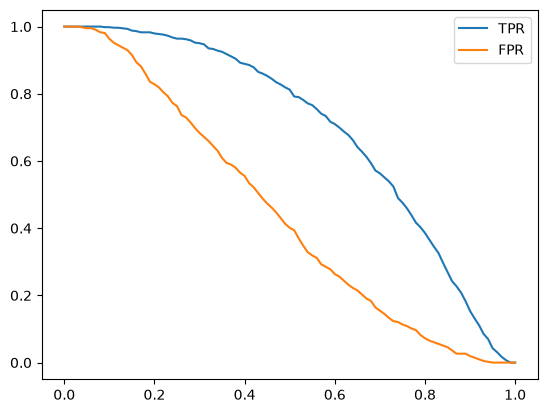

In [206]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [207]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [208]:
y_rand.round(3)

array([0.417, 0.72 , 0.   , 0.302, 0.147, 0.092, 0.186, 0.346, 0.397,
       0.539, 0.419, 0.685, 0.204, 0.878, 0.027, 0.67 , 0.417, 0.559,
       0.14 , 0.198, 0.801, 0.968, 0.313, 0.692, 0.876, 0.895, 0.085,
       0.039, 0.17 , 0.878, 0.098, 0.421, 0.958, 0.533, 0.692, 0.316,
       0.687, 0.835, 0.018, 0.75 , 0.989, 0.748, 0.28 , 0.789, 0.103,
       0.448, 0.909, 0.294, 0.288, 0.13 , 0.019, 0.679, 0.212, 0.266,
       0.492, 0.053, 0.574, 0.147, 0.589, 0.7  , 0.102, 0.414, 0.694,
       0.414, 0.05 , 0.536, 0.664, 0.515, 0.945, 0.587, 0.903, 0.137,
       0.139, 0.807, 0.398, 0.165, 0.928, 0.348, 0.751, 0.726, 0.883,
       0.624, 0.751, 0.349, 0.27 , 0.896, 0.428, 0.965, 0.663, 0.622,
       0.115, 0.949, 0.45 , 0.578, 0.408, 0.237, 0.903, 0.574, 0.003,
       0.617, 0.327, 0.527, 0.886, 0.357, 0.909, 0.623, 0.016, 0.929,
       0.691, 0.997, 0.172, 0.137, 0.933, 0.697, 0.066, 0.755, 0.754,
       0.923, 0.712, 0.124, 0.02 , 0.026, 0.028, 0.246, 0.86 , 0.539,
       0.553, 0.842,

In [209]:
((y_rand>=0.5) == y_val).mean()

np.float64(0.506)

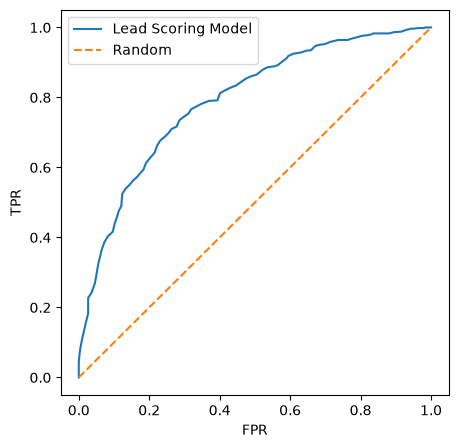

In [210]:
plt.figure(figsize=(5, 5))

plt.plot(
    df_scores.fpr,
    df_scores.tpr,
    label='Lead Scoring Model'
)

plt.plot(
    [0, 1],
    [0, 1],
    label='Random',
    linestyle='--'
)

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [211]:
from sklearn.metrics import roc_curve

In [212]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

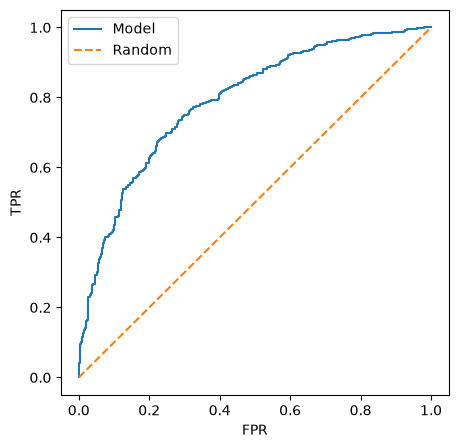

In [213]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [214]:
from sklearn.metrics import auc

In [215]:
auc(fpr, tpr)

0.7905640467593279

In [216]:
auc(df_scores.fpr, df_scores.tpr)

0.7904816078877512

In [217]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val, y_pred)

0.7905640467593279

In [218]:
neg=y_pred[y_val==0]
pos=y_pred[y_val==1]

In [219]:
import random

In [225]:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.78744)

In [232]:
def train(df_train, y_train ,C =1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C ,max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [233]:
dv , model = train(df_train , y_train ,C=0.001)

In [234]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [235]:
y_pred = predict(df_val, dv, model)

In [236]:
from sklearn.model_selection import KFold

In [237]:
kfold = KFold(n_splits=10, shuffle=True, random_state=1)

In [238]:
!pip install tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [239]:
from tqdm.auto import tqdm

In [241]:
n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.783 +- 0.011


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.01 0.789 +- 0.011


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.1 0.791 +- 0.011


... (5 outputs left out)

C=5 0.792 +- 0.012


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=10 0.791 +- 0.011


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [242]:
scores

[0.7779682233991334,
 0.7870952166150992,
 0.7979546390690968,
 0.8099400072834608,
 0.7835365853658536]

In [243]:
np.mean(scores), np.std(scores)

(np.float64(0.7912989343465288), np.float64(0.01137911388835147))

In [244]:
print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.791 +- 0.011


In [245]:
dv, model = train(df_full_train, df_full_train.converted.values, C=5.0)
y_pred = predict(df_test, dv, model)
auc = roc_auc_score(y_test, y_pred)
auc

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.794384943922796